In [191]:
import torch
import numpy
from matplotlib import pyplot

import importlib
import velocity_model
import estimate_velocity
importlib.reload(velocity_model)
importlib.reload(estimate_velocity)

L = 5e6
Growthrate = torch.tensor([1/(20*60)], dtype=torch.double)
v0 = 1e3
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
delay = torch.tensor([360.0, 0.0], dtype=torch.double)
h_tgrid = torch.linspace(0, 0.6*Tr, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

mtrue = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
mtrue.growthrate = Growthrate
mtrue.delay = delay
mtrue.v0 = torch.tensor([v0], dtype=torch.double)
mtrue.h_log_raw = torch.log(torch.tensor([1, 1, 1.5, 2, 1.5, 1, 0.5, 0.1, 0.5, 1, 1], dtype=torch.double))
mtrue.g_log = torch.log(torch.tensor([10, 2], dtype=torch.double))

coverage = 1e3
x = torch.linspace(0, L, steps=1000)
y_obs = torch.poisson(mtrue.P(x) * coverage).detach().numpy()
s_obs = numpy.sqrt(y_obs)

In [192]:
h_tgrid_dense = torch.linspace(0, Tr, steps=1000, dtype=torch.double)
m = velocity_model.VelocityModel(L, True, origins, h_tgrid_dense, g_xranges_l, g_xranges_u)
m.growthrate = Growthrate
m.g_sigma = torch.tensor([10], dtype=torch.double)
m.h_sigma = torch.tensor([10], dtype=torch.double)
m.h_timescale = torch.nn.Parameter(torch.tensor([250], dtype=torch.double))

#torch.autograd.set_detect_anomaly(True)
l = velocity_model.VelocityModelLoss(x, torch.tensor(y_obs), torch.tensor(s_obs), m)
fit = estimate_velocity.FitVelocityModel(m, l)
a, b = fit.optimize_parameters()

In [193]:
print(b["state"][0]["n_iter"])

5000


In [194]:
for n, p in m.named_parameters():
    print(f"{n}: {p}")
    print(f"grad {n}: {p.grad}")

h_timescale: Parameter containing:
tensor([250.], dtype=torch.float64, requires_grad=True)
grad h_timescale: None
v0: Parameter containing:
tensor([1050.5346], dtype=torch.float64, requires_grad=True)
grad v0: tensor([8.4172e-05], dtype=torch.float64)
g_log: Parameter containing:
tensor([2.3016, 0.6677], dtype=torch.float64, requires_grad=True)
grad g_log: tensor([ 3.2459e-05, -1.5932e-02], dtype=torch.float64)
h_log_raw: Parameter containing:
tensor([ 1.2676e-08,  5.4911e-08,  2.7686e-08,  4.1380e-06,  1.6198e-05,
         1.8060e-05, -8.1606e-06, -8.0404e-04,  5.4676e-03,  1.0719e-03,
        -6.5526e-02, -1.0468e-01,  2.8043e-01,  1.1066e+00,  9.9684e-01,
         1.8728e+00, -1.6878e+00, -4.6389e+00, -3.3169e-01,  9.6870e-01,
         2.6454e-01, -7.5905e-01,  3.8213e+00,  8.9701e+00, -6.4374e+00,
        -3.2986e+00,  9.5322e+00,  1.5239e+00,  7.0948e+00],
       dtype=torch.float64, requires_grad=True)
grad h_log_raw: tensor([-4.2670e-02, -3.8317e-02, -5.5314e-03, -3.6850e-03, -3

Text(0, 0.5, 'abundance [reads]')

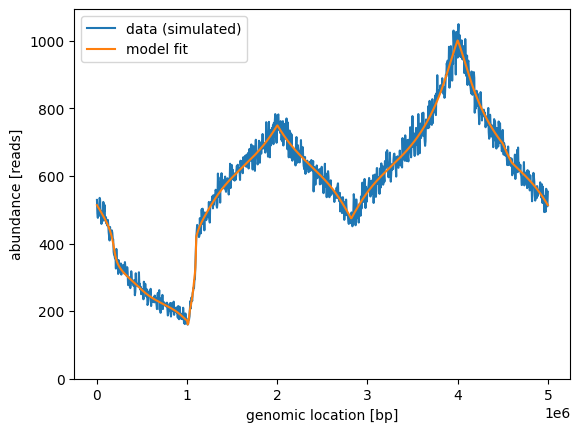

In [195]:
pyplot.plot(fit.loss.x, fit.loss.y_obs.detach(), label="data (simulated)")
pyplot.plot(fit.loss.x, fit.loss.y_pred().detach(), label="model fit")
pyplot.legend()
pyplot.ylim(ymin=0)
pyplot.xlabel("genomic location [bp]")
pyplot.ylabel("abundance [reads]")

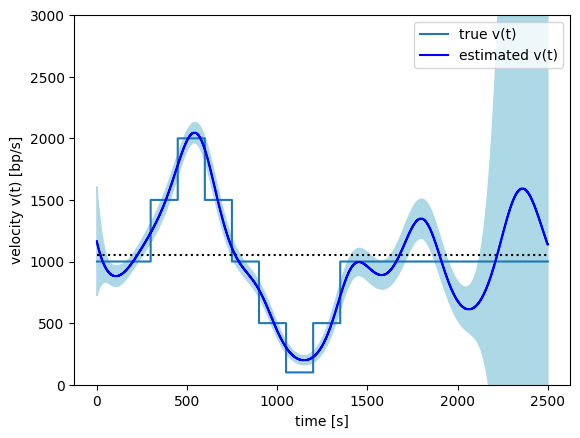

In [196]:
pyplot.step(h_tgrid_dense, mtrue.v_t(h_tgrid_dense).detach(), label="true v(t)")
p_cov, p_pmap = fit.parameter_posterior_cov()
i, l = p_pmap["h_log_raw"], torch.numel(m.h_log_raw)
v_t = m.v_t(fit.model.h_tgrid).detach()
v_t_stderr = m.v_t_posterior_stderr(fit.model.h_tgrid, p_cov, p_pmap).detach()
pyplot.hlines([m.v0.detach()], xmin=0, xmax=m.h_tgrid.max(),
              linestyle="dotted", color="black")
pyplot.step(h_tgrid_dense, v_t, label="estimated v(t)", color="blue")
pyplot.fill_between(h_tgrid_dense,  v_t - v_t_stderr, v_t + v_t_stderr, color="lightblue")
pyplot.xlabel("time [s]")
pyplot.ylabel("velocity v(t) [bp/s]")
pyplot.ylim([0, 3000])
pyplot.legend()